In [1]:
import torch

# The PointNeRF rendering allocates tensors whose size depends on how many ray samples hit the
# point cloud, i.e. it differs for every sample and pose. With the default caching allocator, these
# varying sizes fragment the large block pool until cudaMalloc fails. Expandable segments avoid
# this at no runtime cost. Has to be set before torch initializes CUDA. The setting is not
# available in the original environment (PyTorch 1.12) and is silently skipped there.
try:
    torch._C._accelerator_setAllocatorSettings("expandable_segments:True")
except (AttributeError, RuntimeError):
    pass

import numpy as np

from npcd.models import NPCD
from npcd.utils import load_config, set_seed, to_torch
from npcd.utils.vis import vis, hcat


torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

/home/schroepp/miniforge3/envs/npcd/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
config = load_config("configs/npcd_srncars.yaml")

model = NPCD(use_flash_attn=True, **config["model"])
model.load_state_dict(torch.load("weights/npcd_srncars.pt"))
model.eval().cuda()
autocast_ctx = torch.amp.autocast('cuda', dtype=torch.float16, enabled=True)

In [3]:
set_seed(4057)

# Generate 1 object:
with torch.no_grad(), autocast_ctx:
    coords, feats = model.diffusion.generate(num=1, batch_size=1)  # (num_objects, 3, num_points) and (num_objects, feats_dim, num_points)
coords, feats = coords[0], feats[0]

Setting random seed to: 4057


100%|██████████| 1000/1000 [00:10<00:00, 93.07it/s]


In [4]:
# Get data and prepare for rendering:
resolution = 128  # resolution for the rendered images
pose = np.load(config["inference"]["test_poses_path"])[64]
intrinsics = np.load(config["inference"]["intrinsics_path"])[64]
pose = to_torch(pose, device=coords.device).float()[None, None]  # (batch, num_views, 4, 4)
intrinsics = to_torch(intrinsics, device=coords.device).float()[None, None]  # (batch, num_views, 3, 3)
intrinsics *= (resolution/128.)

In [5]:
# Render the generated object with the chosen pose and intrinsics and resolution:
coords = coords.float().permute(1, 0)[None].contiguous()  # format required by PointNeRF: (batch, num_points, 3)
feats = feats.float().permute(1, 0)[None].contiguous()  # format required by PointNeRF: (batch, num_points, feats_dim)

with torch.no_grad():
    output = model.pointnerf.render(coords, feats, pose, intrinsics, resolution=resolution)
    image = output.channels  # shape: (batch, num_views, H*W, 3)
    image = image[0,0].transpose(0,1).reshape(3, resolution, resolution).cpu().numpy()
    image = np.clip(image, 0., 1.)

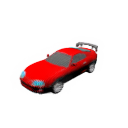

In [6]:
# Visualize the rendered image:
vis(image, image_range_text_off=True, clipping=True, lower_clipping_thresh=0, upper_clipping_thresh=1)

# Extended visualizations

In [7]:
set_seed(4057)

# Generate 1 object (same seed, therefore same object) and keep the intermediate diffusion
# timesteps x_t, as well as the reconstructions x_0 that the model predicts at each timestep:
with torch.no_grad(), autocast_ctx:
    coords_ts, coords_recon, feats_ts, feats_recon = model.diffusion.generate_trajectory(num=1, batch_size=1)  # (num_objects, num_timesteps+1, 3, num_points), (num_objects, num_timesteps, 3, num_points), (num_objects, num_timesteps+1, feats_dim, num_points), (num_objects, num_timesteps, feats_dim, num_points)
coords_ts, feats_ts = coords_ts[0], feats_ts[0]
coords_recon, feats_recon = coords_recon[0], feats_recon[0]

Setting random seed to: 4057


100%|██████████| 1000/1000 [00:10<00:00, 98.91it/s]


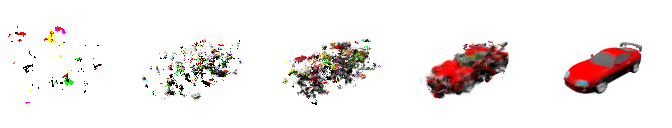

In [8]:
ts_to_render = [-400, -100, -80, -50, -1]
ts_images = []
for ts in ts_to_render:
    coords = coords_ts[ts]
    feats = feats_ts[ts]
    
    coords = coords.float().permute(1, 0)[None].contiguous()  # format required by PointNeRF: (batch, num_points, 3)
    feats = feats.float().permute(1, 0)[None].contiguous()  # format required by PointNeRF: (batch, num_points, feats_dim)

    with torch.no_grad():
        output = model.pointnerf.render(coords, feats, pose, intrinsics, resolution=resolution)
        image = output.channels  # shape: (batch, num_views, H*W, 3)
        image = image[0,0].transpose(0,1).reshape(3, resolution, resolution).cpu().numpy()
        image = np.clip(image, 0., 1.)
        ts_images.append(image)

hcat(*ts_images, image_range_text_off=True, clipping=True, lower_clipping_thresh=0, upper_clipping_thresh=1).vis()

## Spiral trajectory animation

The diffusion timesteps are swept along a full spiral of camera poses, afterwards the final object
is shown for another half spiral.

In [9]:
from io import BytesIO

from IPython.display import Image as IPythonImage, display
from tqdm import tqdm


def take_n_elements(lst, n):
    """Pick n evenly spaced elements from lst, including the first and the last one."""
    if n <= 1 or len(lst) <= 1:
        return lst[:n]
    step = (len(lst) - 1) / (n - 1)
    return [lst[int(round(i * step))] for i in range(n)]


# Animate the noisy states x_t, or the reconstructions x_0 that the model predicts at each timestep:
use_recon = True
trajectory_coords = coords_recon if use_recon else coords_ts
trajectory_feats = feats_recon if use_recon else feats_ts

spiral_poses = np.load(config["inference"]["spiral_poses_path"])  # (num_poses, 4, 4)
num_final_poses = len(spiral_poses) // 2  # number of poses that show the final object at the end

# One diffusion timestep per spiral pose, followed by the final object for half a spiral:
anim_poses = list(spiral_poses) + list(spiral_poses[:num_final_poses])
anim_coords = take_n_elements(list(trajectory_coords), len(spiral_poses)) + [coords_ts[-1]] * num_final_poses
anim_feats = take_n_elements(list(trajectory_feats), len(spiral_poses)) + [feats_ts[-1]] * num_final_poses

In [10]:
# Render one image per animation frame:
anim_images = []
for anim_pose, anim_coords_frame, anim_feats_frame in tqdm(list(zip(anim_poses, anim_coords, anim_feats))):
    anim_pose = to_torch(anim_pose, device=coords_ts.device).float()[None, None]  # (batch, num_views, 4, 4)
    anim_coords_frame = anim_coords_frame.float().permute(1, 0)[None].contiguous()  # (batch, num_points, 3)
    anim_feats_frame = anim_feats_frame.float().permute(1, 0)[None].contiguous()  # (batch, num_points, feats_dim)

    with torch.no_grad():
        output = model.pointnerf.render(anim_coords_frame, anim_feats_frame, anim_pose, intrinsics, resolution=resolution)
        image = output.channels  # shape: (batch, num_views, H*W, 3)
        image = image[0, 0].transpose(0, 1).reshape(3, resolution, resolution).cpu().numpy()
        anim_images.append(np.clip(image, 0., 1.))

100%|██████████| 300/300 [00:05<00:00, 52.63it/s] 


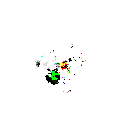

In [11]:
# Assemble the frames into an animated gif and show it (30ms per frame, looping forever):
frames = [vis(image, image_range_text_off=True, clipping=True, lower_clipping_thresh=0, upper_clipping_thresh=1) for image in anim_images]
gif = BytesIO()
frames[0].save(gif, format="GIF", save_all=True, append_images=frames[1:], duration=30, loop=0)

display(IPythonImage(data=gif.getvalue()))